# Ejercicio de Normalización 

![Logo itq](Imagenes/ITQ.png)


**Nombre** Andres Gonzalez 

**Fecha** 9/11/2026

**Link** [Link Repositorio](https://github.com/andresgonzlez896-lang/Fundamentos-ML.git)

**Objetivos**

Aplicar las fases de comprensión del negocio y comprensión de los datos de CRISP-DM, y desarrollar la preparación de datos hasta la normalización Min-Max y la estandarización Z-score, mediante el análisis reproducible de más de 100 000 registros de hospitalizaciones de pacientes con diabetes en Python.

**Antecedentes y escenario**

El conjunto Diabetes 130-US Hospitals for Years 1999–2008, publicado en UCI, contiene 101 766 hospitalizaciones registradas en 130 hospitales y redes de atención de Estados Unidos. Una fila representa una hospitalización, no necesariamente un paciente diferente. Incluye variables demográficas, de atención y de readmisión hospitalaria.

En esta actividad, un equipo de análisis debe comprender la información y preparar variables numéricas con distintas escalas. El análisis es académico y no permite emitir diagnósticos ni establecer relaciones causales.

In [1]:
#Instalar la libreria
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
#Importacion de librerias
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn import preprocessing

## Descarga de los datos

In [3]:
from ucimlrepo import fetch_ucirepo

# Descargar el conjunto de datos desde UCI.
dataset = fetch_ucirepo(id=296)

# Obtener una copia de todos los datos.
df = dataset.data.original.copy()

# Verificar que cumple con el tamaño solicitado.
print("Filas y columnas:", df.shape)
assert len(df) > 100_000, "El dataset debe superar los 100 000 registros."

# Visualizar los primeros registros.
display(df.head())

# Consultar el diccionario de variables.
display(dataset.variables)

# Guardar una copia local para desarrollar la actividad.
df.to_csv("hospitalizaciones_diabetes_original.csv", index=False)

C:\Users\DETPC\anaconda3\Lib\site-packages\ucimlrepo\fetch.py:97: DtypeWarning: Columns (0: payer_code) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Filas y columnas: (101766, 50)


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


,name,role,type,demographic,description,units,missing_values
0,encounter_id,ID,,NaN,Unique identifier of an encounter,None,no
1,patient_nbr,ID,,NaN,Unique identifier of a patient,None,no
2,race,Feature,Categorical,Race,"Values: Caucasian, Asian, African American, Hi...",None,yes
3,gender,Feature,Categorical,Gender,"Values: male, female, and unknown/invalid",None,no
4,age,Feature,Categorical,Age,"Grouped in 10-year intervals: [0, 10), [10, 20...",None,no
5,weight,Feature,Categorical,NaN,Weight in pounds.,None,yes
6,admission_type_id,Feature,Categorical,NaN,Integer identifier corresponding to 9 distinct...,None,no
7,discharge_disposition_id,Feature,Categorical,NaN,Integer identifier corresponding to 29 distinc...,None,no
8,admission_source_id,Feature,Categorical,NaN,Integer identifier corresponding to 21 distinc...,None,no
9,time_in_hospital,Feature,Integer,NaN,Integer number of days between admission and d...,None,no


In [4]:
#Registro de la descarga: fecha, dimensiones y versiones
from datetime import datetime
import sklearn, platform

print("Fecha de descarga:", datetime.now().strftime("%Y-%m-%d %H:%M"))
print("Dimensiones:", df.shape)
print("Python", platform.python_version(), "| pandas", pd.__version__, "| numpy", np.__version__,
      "| seaborn", sns.__version__, "| scikit-learn", sklearn.__version__)

#Copia original que no se modifica
df_original = df.copy()

Fecha de descarga: 2026-11-09 23:08
Dimensiones: (101766, 50)
Python 3.14.6 | pandas 3.0.3 | numpy 2.4.6 | seaborn 0.13.2 | scikit-learn 1.9.0


## Fase 2: Comprensión de los datos

**Reporte las dimensiones reales y distinga número de hospitalizaciones y número de pacientes únicos.**

In [5]:
#Dimensiones, hospitalizaciones y pacientes unicos
print("Filas:", df.shape[0], "| Columnas:", df.shape[1])
print("Hospitalizaciones (encounter_id unicos):", df["encounter_id"].nunique())
print("Pacientes unicos (patient_nbr):", df["patient_nbr"].nunique())
assert df.shape[0] == 101_766, "Se esperaban 101 766 filas."

Filas: 101766 | Columnas: 50
Hospitalizaciones (encounter_id unicos): 101766
Pacientes unicos (patient_nbr): 71518


Hay 101 766 hospitalizaciones, pero menos pacientes únicos: algunos pacientes tienen más de una hospitalización.

In [6]:
#Variables cuantitativas que se van a usar
VARS = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
        "number_outpatient", "number_emergency", "number_inpatient"]

#crear la variable diccionario con las columnas y los tipos de datos que tienen
diccionario = pd.DataFrame({"columna": df.columns,
                            "tipo_observado": df.dtypes.astype(str).values})

#Escribir el significado de cada columna
significado = {
    "encounter_id": "Identificador único de la hospitalización",
    "patient_nbr": "Identificador del paciente (se repite si tiene varias hospitalizaciones)",
    "race": "Raza del paciente (? = faltante)",
    "gender": "Género del paciente",
    "age": "Edad agrupada en intervalos de 10 años",
    "weight": "Peso del paciente en libras, por intervalos (? = faltante)",
    "admission_type_id": "Código del tipo de admisión (emergencia, urgencia, electiva, etc.)",
    "discharge_disposition_id": "Código del destino al alta (domicilio, traslado, fallecimiento, etc.)",
    "admission_source_id": "Código de la procedencia del ingreso (derivación, emergencias, etc.)",
    "time_in_hospital": "Duración de la hospitalización en días",
    "payer_code": "Código del pagador o seguro del paciente",
    "medical_specialty": "Especialidad del médico que admitió al paciente",
    "num_lab_procedures": "Número de pruebas de laboratorio durante la hospitalización",
    "num_procedures": "Número de procedimientos distintos de laboratorio",
    "num_medications": "Número de medicamentos distintos administrados",
    "number_outpatient": "Visitas ambulatorias del paciente en el año previo",
    "number_emergency": "Visitas de emergencia del paciente en el año previo",
    "number_inpatient": "Hospitalizaciones del paciente en el año previo",
    "diag_1": "Diagnóstico principal (código ICD-9)",
    "diag_2": "Diagnóstico secundario (código ICD-9)",
    "diag_3": "Diagnóstico secundario adicional (código ICD-9)",
    "number_diagnoses": "Número de diagnósticos registrados",
    "max_glu_serum": "Resultado de glucosa sérica (>200, >300, Norm, None = no se midió)",
    "A1Cresult": "Resultado de hemoglobina A1c (>8, >7, Norm, None = no se midió)",
    "change": "Hubo cambio en los medicamentos para diabetes (Ch = cambio, No)",
    "diabetesMed": "Se prescribió algún medicamento para diabetes (Yes / No)",
    "readmitted": "Readmisión: NO (sin reingreso), <30 (menos de 30 días), >30 (después de 30 días)",
}
#Las 23 columnas de medicamentos tienen el mismo significado
medicamentos = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide",
                "glipizide", "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol",
                "troglitazone", "tolazamide", "examide", "citoglipton", "insulin", "glyburide-metformin",
                "glipizide-metformin", "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone"]
for m in medicamentos:
    significado[m] = f"Indica si se prescribió {m} y si la dosis cambió (No, Steady, Up, Down)"

diccionario["significado"] = diccionario["columna"].map(significado)

#Tipo conceptual, unidades/categorías y rol
def tipo_conceptual(c):
    if c in ["encounter_id", "patient_nbr"]:
        return "Identificador"
    if c in VARS + ["number_diagnoses"]:
        return "Cuantitativa discreta"
    if c in ["age", "weight"]:
        return "Categórica ordinal (intervalos)"
    return "Categórica"

def rol(c):
    if c in ["encounter_id", "patient_nbr"]:
        return "Referencia (no se escala)"
    if c in VARS:
        return "Variable a escalar"
    if c == "readmitted":
        return "Variable de referencia (no se escala)"
    return "Otra característica"

diccionario["tipo_conceptual"] = diccionario["columna"].apply(tipo_conceptual)
diccionario["unidades_o_categorias"] = diccionario["columna"].apply(
    lambda c: "Días" if c == "time_in_hospital" else ("Cantidad (conteo)" if c in VARS + ["number_diagnoses"] else
              "Códigos o categorías"))
diccionario["rol_analitico"] = diccionario["columna"].apply(rol)

#Verificar que todas las columnas tienen significado
assert diccionario["significado"].notna().all()

#mostrar la tabla
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 80)
display(diccionario)

,columna,tipo_observado,significado,tipo_conceptual,unidades_o_categorias,rol_analitico
0,encounter_id,int64,Identificador único de la hospitalización,Identificador,Códigos o categorías,Referencia (no se escala)
1,patient_nbr,int64,Identificador del paciente (se repite si tiene varias hospitalizaciones),Identificador,Códigos o categorías,Referencia (no se escala)
2,race,str,Raza del paciente (? = faltante),Categórica,Códigos o categorías,Otra característica
3,gender,str,Género del paciente,Categórica,Códigos o categorías,Otra característica
4,age,str,Edad agrupada en intervalos de 10 años,Categórica ordinal (intervalos),Códigos o categorías,Otra característica
5,weight,str,"Peso del paciente en libras, por intervalos (? = faltante)",Categórica ordinal (intervalos),Códigos o categorías,Otra característica
6,admission_type_id,int64,"Código del tipo de admisión (emergencia, urgencia, electiva, etc.)",Categórica,Códigos o categorías,Otra característica
7,discharge_disposition_id,int64,"Código del destino al alta (domicilio, traslado, fallecimiento, etc.)",Categórica,Códigos o categorías,Otra característica
8,admission_source_id,int64,"Código de la procedencia del ingreso (derivación, emergencias, etc.)",Categórica,Códigos o categorías,Otra característica
9,time_in_hospital,int64,Duración de la hospitalización en días,Cuantitativa discreta,Días,Variable a escalar


Los identificadores (`encounter_id`, `patient_nbr`) y los códigos (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`) están guardados como números, pero **no son mediciones**. Las variables cuantitativas reales son los días y los conteos.

**Cuantifique datos faltantes por columna en número y porcentaje. Revise nulos y marcadores como ?. Consulte el significado de categorías como None antes de tratarlas como ausencia de información.**

In [7]:
#Contamos los nulos (NaN) y el marcador "?" por columna
nulos = df.isnull().sum()
interrogantes = (df.astype("object") == "?").sum()

faltantes = pd.DataFrame({"nulos": nulos, "signo_?": interrogantes})
faltantes["total"] = faltantes["nulos"] + faltantes["signo_?"]
faltantes["porcentaje"] = faltantes["total"] / len(df) * 100

#mostramos solo las columnas con faltantes
display(faltantes[faltantes["total"] > 0].sort_values("porcentaje", ascending=False))

,nulos,signo_?,total,porcentaje
weight,98569,0,98569,96.858479
max_glu_serum,96420,0,96420,94.746772
A1Cresult,84748,0,84748,83.277322
medical_specialty,49949,0,49949,49.082208
payer_code,40256,0,40256,39.557416
race,2273,0,2273,2.233555
diag_3,1423,0,1423,1.398306
diag_2,358,0,358,0.351787
diag_1,21,0,21,0.020636


In [8]:
#Revisamos la categoria "None" (en estas columnas significa que la prueba NO se realizó)
print(df["max_glu_serum"].value_counts(dropna=False))
print()
print(df["A1Cresult"].value_counts(dropna=False))

max_glu_serum
NaN     96420
Norm     2597
>200     1485
>300     1264
Name: count, dtype: int64

A1Cresult
NaN     84748
>8       8216
Norm     4990
>7       3812
Name: count, dtype: int64


`weight` tiene casi todos sus datos faltantes (alrededor del 97 %), y `medical_specialty` y `payer_code` también tienen muchos. En `max_glu_serum` y `A1Cresult` la categoría `None` significa que **la prueba no se realizó**, por lo que es información y no un dato perdido. Nota: en versiones nuevas de pandas la palabra "None" se lee como nulo (`NaN`), por eso puede aparecer así en la tabla; en la limpieza se trata como una categoría.

**Revise duplicados de filas e identificadores. La repetición de patient_nbr puede representar hospitalizaciones válidas; no la elimine automáticamente.**

In [9]:
#Duplicados de filas completas
dup_filas = df.duplicated().sum()
print("Filas completamente duplicadas:", dup_filas)
print(f"Porcentaje: {dup_filas / len(df) * 100:.2f}%")

#Duplicados en encounter_id (debe ser único: una fila = una hospitalización)
dup_encuentros = df["encounter_id"].duplicated().sum()
print("encounter_id repetidos:", dup_encuentros)

#Pacientes con mas de una hospitalizacion (esto NO es un duplicado)
por_paciente = df.groupby("patient_nbr").size()
print("Pacientes con más de una hospitalización:", (por_paciente > 1).sum(), "de", len(por_paciente))
print("Máximo de hospitalizaciones de un mismo paciente:", por_paciente.max())

Filas completamente duplicadas: 0
Porcentaje: 0.00%
encounter_id repetidos: 0
Pacientes con más de una hospitalización: 16773 de 71518
Máximo de hospitalizaciones de un mismo paciente: 40


No hay filas duplicadas ni `encounter_id` repetidos. Hay pacientes con varias hospitalizaciones, pero son eventos distintos (readmisiones), por eso **no se eliminan**.

**Calcule mínimo, máximo, media, mediana, desviación estándar y cuartiles de las variables cuantitativas. Analice también las frecuencias de readmitted.**

In [10]:
#Analisis exploratorio de las 7 variables cuantitativas
X = df[VARS]
X.describe()

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
count,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000,101766.000000
mean,4.395987,43.095641,1.339730,16.021844,0.369357,0.197836,0.635566
std,2.985108,19.674362,1.705807,8.127566,1.267265,0.930472,1.262863
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2.000000,31.000000,0.000000,10.000000,0.000000,0.000000,0.000000
50%,4.000000,44.000000,1.000000,15.000000,0.000000,0.000000,0.000000
75%,6.000000,57.000000,2.000000,20.000000,0.000000,0.000000,1.000000
max,14.000000,132.000000,6.000000,81.000000,42.000000,76.000000,21.000000


In [11]:
#La mediana es el cuartil 50%. Agregamos la asimetria para ver la forma
print("Asimetría de cada variable:")
print(X.skew())

#Frecuencias de readmitted
frecuencia = df["readmitted"].value_counts()
print("\nFrecuencias de readmitted:")
print(pd.DataFrame({"n": frecuencia, "porcentaje": frecuencia / len(df) * 100}))

Asimetría de cada variable:
time_in_hospital       1.133999
num_lab_procedures    -0.236544
num_procedures         1.316415
num_medications        1.326672
number_outpatient      8.832959
number_emergency      22.855582
number_inpatient       3.614139
dtype: float64

Frecuencias de readmitted:
                n  porcentaje
readmitted                   
NO          54864   53.911916
>30         35545   34.928169
<30         11357   11.159916


Las variables de visitas previas (`number_outpatient`, `number_emergency`, `number_inpatient`) están concentradas en 0 y tienen cola larga a la derecha. `time_in_hospital` y `num_medications` también son asimétricas a la derecha; `num_lab_procedures` es la más simétrica. En `readmitted`, `NO` es la categoría más frecuente y `<30` la menos frecuente: las clases están desbalanceadas.

**Construya al menos cuatro visualizaciones: histogramas y diagramas de caja de dos variables cuantitativas. Añada un gráfico de frecuencias de readmitted e interprete cada resultado.**

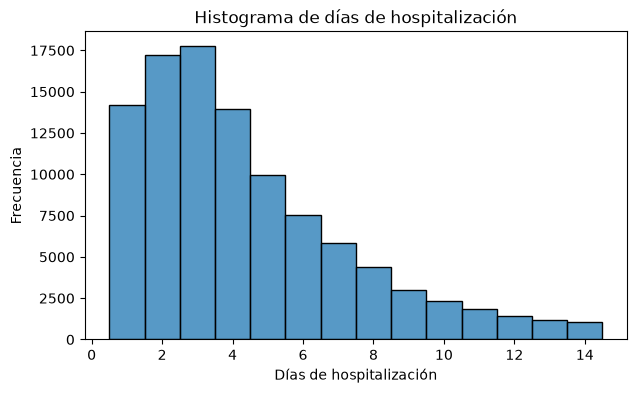

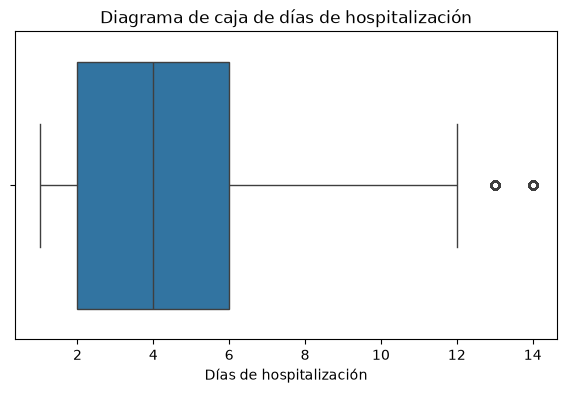

In [12]:
# Gráfico 1: Histograma de time_in_hospital
plt.figure(figsize=(7, 4))
sns.histplot(df["time_in_hospital"], discrete=True)
plt.title("Histograma de días de hospitalización")
plt.xlabel("Días de hospitalización")
plt.ylabel("Frecuencia")
plt.show()

# Gráfico 2: Diagrama de caja de time_in_hospital
plt.figure(figsize=(7, 4))
sns.boxplot(x=df["time_in_hospital"])
plt.title("Diagrama de caja de días de hospitalización")
plt.xlabel("Días de hospitalización")
plt.show()

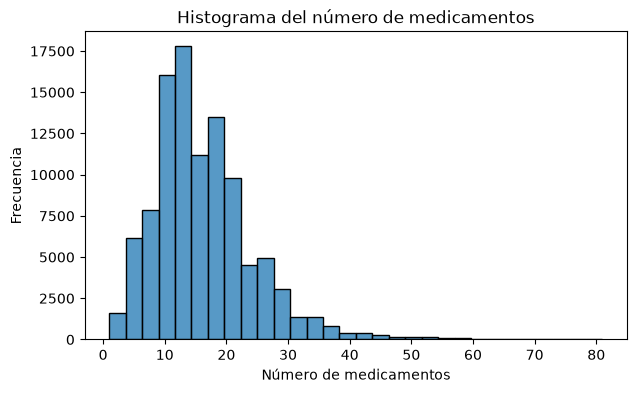

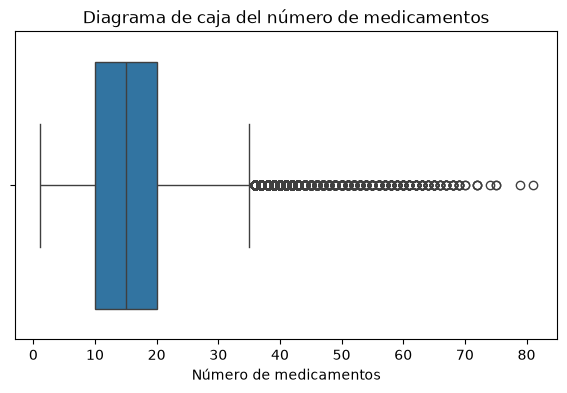

In [13]:
# Gráfico 3: Histograma de num_medications
plt.figure(figsize=(7, 4))
sns.histplot(df["num_medications"], bins=30)
plt.title("Histograma del número de medicamentos")
plt.xlabel("Número de medicamentos")
plt.ylabel("Frecuencia")
plt.show()

# Gráfico 4: Diagrama de caja de num_medications
plt.figure(figsize=(7, 4))
sns.boxplot(x=df["num_medications"])
plt.title("Diagrama de caja del número de medicamentos")
plt.xlabel("Número de medicamentos")
plt.show()

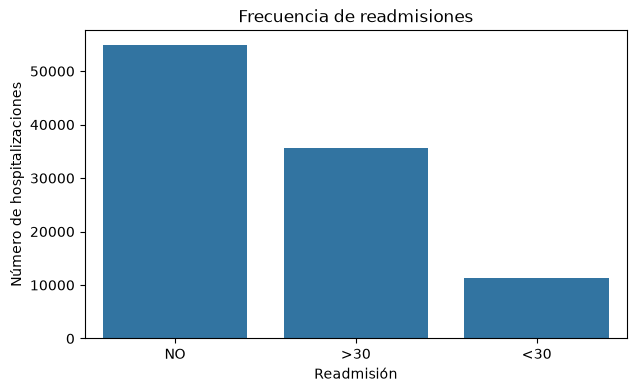

In [14]:
# Gráfico 5: Frecuencias de readmitted
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="readmitted", order=["NO", ">30", "<30"])
plt.title("Frecuencia de readmisiones")
plt.xlabel("Readmisión")
plt.ylabel("Número de hospitalizaciones")
plt.show()

In [15]:
# Outliers por IQR en las 7 variables
def atipicos_iqr(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    iqr = q3 - q1
    inf = q1 - 1.5 * iqr
    sup = q3 + 1.5 * iqr
    mask = (serie < inf) | (serie > sup)
    return {"Q1": q1, "Q3": q3, "IQR": iqr, "limite_inf": inf, "limite_sup": sup,
            "atipicos": int(mask.sum()), "porcentaje": mask.mean() * 100}

tabla_iqr = pd.DataFrame({v: atipicos_iqr(df[v]) for v in VARS}).T
tabla_iqr["atipicos"] = tabla_iqr["atipicos"].astype(int)
display(tabla_iqr)

,Q1,Q3,IQR,limite_inf,limite_sup,atipicos,porcentaje
time_in_hospital,2.0,6.0,4.0,-4.0,12.0,2252,2.212920
num_lab_procedures,31.0,57.0,26.0,-8.0,96.0,143,0.140518
num_procedures,0.0,2.0,2.0,-3.0,5.0,4954,4.868031
num_medications,10.0,20.0,10.0,-5.0,35.0,2557,2.512627
number_outpatient,0.0,0.0,0.0,0.0,0.0,16739,16.448519
number_emergency,0.0,0.0,0.0,0.0,0.0,11383,11.185465
number_inpatient,0.0,1.0,1.0,-1.5,2.5,7049,6.926675


## Fase 3: Selección y limpieza

**Defina reglas explícitas para valores faltantes, duplicados e inconsistencias. Registre las filas y columnas antes y después de cada decisión.**



In [16]:
#Registro de limpieza: filas y columnas antes y despues de cada regla
registro = []
def registrar(regla, antes, despues, detalle):
    registro.append({"regla": regla,
                     "filas_antes": antes.shape[0], "cols_antes": antes.shape[1],
                     "filas_despues": despues.shape[0], "cols_despues": despues.shape[1],
                     "detalle": detalle})

df_clean = df_original.copy()

#Regla 1: "?" -> NaN (solo en columnas de texto)
antes = df_clean
cols_texto = [c for c in df_clean.columns if not pd.api.types.is_numeric_dtype(df_clean[c])]
n_int = int((df_clean[cols_texto].astype("object") == "?").sum().sum())
for c in cols_texto:
    df_clean[c] = df_clean[c].replace("?", np.nan)
registrar("1. ? -> NaN", antes, df_clean, f"{n_int} celdas")

#Regla 2: "None" = prueba no realizada -> "No_medido"
antes = df_clean
for c in ["max_glu_serum", "A1Cresult"]:
    df_clean[c] = df_clean[c].replace("None", np.nan).fillna("No_medido")
registrar("2. None -> No_medido", antes, df_clean, "max_glu_serum y A1Cresult")

#Regla 3: quitar columnas con mas de 90% de faltantes
antes = df_clean
porc = df_clean.isnull().mean() * 100
quitar = porc[porc > 90].index.tolist()
df_clean = df_clean.drop(columns=quitar)
registrar("3. Quitar columnas > 90% faltantes", antes, df_clean, str(quitar))

#Regla 4: faltantes categoricos y genero invalido -> "Desconocido"
antes = df_clean
df_clean["gender"] = df_clean["gender"].replace("Unknown/Invalid", np.nan)
cols_con_nulos = [c for c in df_clean.columns if df_clean[c].isnull().any()]
for c in cols_con_nulos:
    if pd.api.types.is_numeric_dtype(df_clean[c]):
        raise ValueError(f"Hay faltantes en la columna numérica {c}")
    df_clean[c] = df_clean[c].fillna("Desconocido")
registrar("4. Faltantes -> Desconocido", antes, df_clean, str(cols_con_nulos))

#Regla 5: duplicados exactos y encounter_id repetidos (patient_nbr NO se toca)
antes = df_clean
n_dup = int(df_clean.duplicated().sum()) + int(df_clean["encounter_id"].duplicated().sum())
df_clean = df_clean.drop_duplicates().drop_duplicates(subset="encounter_id")
registrar("5. Duplicados", antes, df_clean, f"{n_dup} duplicados encontrados")

#Regla 6: rangos validos de las 7 variables
antes = df_clean
invalidos = ((df_clean[VARS] < 0).any(axis=1)
             | (df_clean[VARS] % 1 != 0).any(axis=1)
             | ~df_clean["time_in_hospital"].between(1, 14))
df_clean = df_clean[~invalidos]
registrar("6. Rangos válidos", antes, df_clean, f"{int(invalidos.sum())} filas inválidas")

#Regla 7: codigos -> categoria (cambio de tipo)
antes = df_clean
CODIGOS = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]
for c in CODIGOS:
    df_clean[c] = df_clean[c].astype("category")
registrar("7. Códigos a categoría", antes, df_clean, str(CODIGOS))

display(pd.DataFrame(registro))

,regla,filas_antes,cols_antes,filas_despues,cols_despues,detalle
0,1. ? -> NaN,101766,50,101766,50,0 celdas
1,2. None -> No_medido,101766,50,101766,50,max_glu_serum y A1Cresult
2,3. Quitar columnas > 90% faltantes,101766,50,101766,49,['weight']
3,4. Faltantes -> Desconocido,101766,49,101766,49,"['race', 'gender', 'payer_code', 'medical_specialty', 'diag_1', 'diag_2', 'd..."
4,5. Duplicados,101766,49,101766,49,0 duplicados encontrados
5,6. Rangos válidos,101766,49,101766,49,0 filas inválidas
6,7. Códigos a categoría,101766,49,101766,49,"['admission_type_id', 'discharge_disposition_id', 'admission_source_id']"


In [17]:
#Comprobaciones finales de la limpieza
print("Filas:", len(df_original), "->", len(df_clean))
print("Columnas:", df_original.shape[1], "->", df_clean.shape[1])
print("Nulos restantes:", int(df_clean.isnull().sum().sum()))

assert len(df_clean) > 100_000, "Debe seguir habiendo más de 100 000 filas."
assert df_clean.isnull().sum().sum() == 0
assert df_clean["encounter_id"].is_unique

#Guardamos el conjunto limpio
df_clean.to_csv("hospitalizaciones_diabetes_limpio.csv", index=True, index_label="indice_referencia")

Filas: 101766 -> 101766
Columnas: 50 -> 49
Nulos restantes: 0


In [18]:
#Separamos los datos de entrada (7 variables) de nuestra variable de referencia
X = df_clean[VARS].astype("int64").copy()
X.index.name = "indice_referencia"
y = df_clean["readmitted"]

#Verificamos tipo, valores unicos, minimo, maximo y nulos de cada variable
verificacion = pd.DataFrame({"tipo": X.dtypes.astype(str), "unicos": X.nunique(),
                             "min": X.min(), "max": X.max(), "nulos": X.isnull().sum()})
display(verificacion)

#Variables constantes (si hubiera alguna)
constantes = verificacion.index[verificacion["unicos"] == 1].tolist()
print("Columnas constantes:", constantes if constantes else "ninguna")

,tipo,unicos,min,max,nulos
time_in_hospital,int64,14,1,14,0
num_lab_procedures,int64,118,1,132,0
num_procedures,int64,7,0,6,0
num_medications,int64,75,1,81,0
number_outpatient,int64,39,0,42,0
number_emergency,int64,33,0,76,0
number_inpatient,int64,21,0,21,0


Columnas constantes: ninguna


## Normalización 

**Fórmula:** $x_{nuevo} = \frac{x - x_{min}}{x_{max} - x_{min}}$

Se aplica `MinMaxScaler` con rango [0, 1] sobre una copia de las 7 variables limpias.

In [19]:
#Normalizamos el conjunto de datos
normalizer = preprocessing.MinMaxScaler()
X_norm = normalizer.fit_transform(X.copy())
X_norm = pd.DataFrame(X_norm, columns=X.columns, index=X.index)

#Primeras diez filas
X_norm.head(10)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
indice_referencia,,,,,,,
0,0.000000,0.305344,0.000000,0.0000,0.000000,0.0,0.000000
1,0.153846,0.442748,0.000000,0.2125,0.000000,0.0,0.000000
2,0.076923,0.076336,0.833333,0.1500,0.047619,0.0,0.047619
3,0.076923,0.328244,0.166667,0.1875,0.000000,0.0,0.000000
4,0.000000,0.381679,0.000000,0.0875,0.000000,0.0,0.000000
5,0.153846,0.229008,1.000000,0.1875,0.000000,0.0,0.000000
6,0.230769,0.526718,0.166667,0.2500,0.000000,0.0,0.000000
7,0.307692,0.549618,0.000000,0.1375,0.000000,0.0,0.000000
8,0.923077,0.511450,0.333333,0.3375,0.000000,0.0,0.000000


In [20]:
#Tabla con minimo y maximo antes y despues
comparacion = pd.DataFrame({"min_antes": X.min(), "max_antes": X.max(),
                            "min_despues": X_norm.min(), "max_despues": X_norm.max()})
display(comparacion)

#Comprobamos el rango [0, 1] con tolerancia
tol = 1e-9
no_constantes = [c for c in X.columns if c not in constantes]
assert np.allclose(X_norm[no_constantes].min(), 0, atol=tol)
assert np.allclose(X_norm[no_constantes].max(), 1, atol=tol)
assert X_norm.index.equals(X.index)
print("Comprobación superada: todas las variables están entre 0 y 1")

,min_antes,max_antes,min_despues,max_despues
time_in_hospital,1,14,0.0,1.0
num_lab_procedures,1,132,0.0,1.0
num_procedures,0,6,0.0,1.0
num_medications,1,81,0.0,1.0
number_outpatient,0,42,0.0,1.0
number_emergency,0,76,0.0,1.0
number_inpatient,0,21,0.0,1.0


Comprobación superada: todas las variables están entre 0 y 1


In [21]:
#Influencia de los valores extremos: % de datos que quedan por debajo de 0.10
print((X_norm < 0.10).mean() * 100)

#Ejemplo pequeño: con y sin un valor extremo
ejemplo = pd.DataFrame({"sin_extremo": [1, 2, 3, 4, 5], "con_extremo": [1, 2, 3, 4, 100]})
print()
print(pd.DataFrame(preprocessing.MinMaxScaler().fit_transform(ejemplo), columns=ejemplo.columns))

#Columna constante: (x_max - x_min) = 0
const = pd.DataFrame({"constante": [5, 5, 5, 5], "variable": [1, 2, 3, 4]})
print()
print(pd.DataFrame(preprocessing.MinMaxScaler().fit_transform(const), columns=const.columns))

time_in_hospital      30.886544
num_lab_procedures    10.138946
num_procedures        45.842423
num_medications       15.331250
number_outpatient     98.568284
number_emergency      99.797575
number_inpatient      93.073325
dtype: float64

   sin_extremo  con_extremo
0         0.00     0.000000
1         0.25     0.010101
2         0.50     0.020202
3         0.75     0.030303
4         1.00     1.000000

   constante  variable
0        0.0  0.000000
1        0.0  0.333333
2        0.0  0.666667
3        0.0  1.000000


**Explicación.** Min-Max usa solo el mínimo y el máximo. Si hay un valor extremo, el denominador $x_{max} - x_{min}$ se hace muy grande y el resto de los datos queda **comprimido cerca de 0** (en el ejemplo, al cambiar 5 por 100 los valores 1 a 4 quedan casi en 0). Si una columna es constante, el denominador sería 0; `MinMaxScaler` lo controla y devuelve 0 en toda la columna.

## Estandarización

**Fórmula:** $z = \frac{x - \mu}{\sigma}$

Se aplica `StandardScaler` sobre **otra copia** de las variables limpias originales (no sobre el resultado de Min-Max).

In [22]:
#Estandarización
standarizer = preprocessing.StandardScaler()
#Estandarizamos los datos
X_std = standarizer.fit_transform(X.copy())
X_std = pd.DataFrame(X_std, columns=X.columns, index=X.index)

#Primeras diez filas
X_std.head(10)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient
indice_referencia,,,,,,,
0,-1.137649,-0.106517,-0.785398,-1.848268,-0.291461,-0.21262,-0.503276
1,-0.467653,0.808384,-0.785398,0.243390,-0.291461,-0.21262,-0.503276
2,-0.802651,-1.631351,2.145781,-0.371804,1.286748,-0.21262,0.288579
3,-0.802651,0.045967,-0.199162,-0.002688,-0.291461,-0.21262,-0.503276
4,-1.137649,0.401761,-0.785398,-0.986997,-0.291461,-0.21262,-0.503276
5,-0.467653,-0.614795,2.732016,-0.002688,-0.291461,-0.21262,-0.503276
6,-0.132655,1.367490,-0.199162,0.612506,-0.291461,-0.21262,-0.503276
7,0.202343,1.519973,-0.785398,-0.494842,-0.291461,-0.21262,-0.503276
8,2.882327,1.265834,0.387074,1.473776,-0.291461,-0.21262,-0.503276


In [23]:
#Comprobamos media ~ 0 y desviación ~ 1 (ddof=0, igual que StandardScaler)
medias = X_std.mean()
desvs = X_std.std(ddof=0)
display(pd.DataFrame({"media": medias, "desviacion": desvs}))

assert np.allclose(medias, 0, atol=1e-9)
assert np.allclose(desvs[no_constantes], 1, atol=1e-9)
print("Comprobación superada: media ≈ 0 y desviación ≈ 1")

#Valores negativos y fuera de [0, 1]
print("\n% de valores negativos:")
print((X_std < 0).mean() * 100)
print("\nValor máximo de z en cada variable:")
print(X_std.max())

#Columna constante con StandardScaler
res = preprocessing.StandardScaler().fit_transform(const)
print("\nColumna constante estandarizada:", res[:, 0], "| desviación:", res[:, 0].std())

,media,desviacion
time_in_hospital,5.809126e-17,1.0
num_lab_procedures,1.161825e-16,1.0
num_procedures,-6.479410e-17,1.0
num_medications,-1.340568e-16,1.0
number_outpatient,3.574847e-17,1.0
number_emergency,1.787424e-17,1.0
number_inpatient,-3.574847e-17,1.0


Comprobación superada: media ≈ 0 y desviación ≈ 1

% de valores negativos:
time_in_hospital      62.016784
num_lab_procedures    48.463141
num_procedures        66.224476
num_medications       59.622074
number_outpatient     83.551481
number_emergency      88.814535
number_inpatient      66.456380
dtype: float64

Valor máximo de z en cada variable:
time_in_hospital       3.217324
num_lab_procedures     4.518815
num_procedures         2.732016
num_medications        7.994826
number_outpatient     32.850938
number_emergency      81.466733
number_inpatient      16.125684
dtype: float64

Columna constante estandarizada: [0. 0. 0. 0.] | desviación: 0.0


## Comparación y exportación

**Compare datos originales limpios, normalizados y estandarizados en una tabla de estadísticas.**

In [24]:
#Tabla comparativa (desviación con ddof=0)
def estadisticas(d, nombre):
    t = pd.DataFrame({"min": d.min(), "max": d.max(), "media": d.mean(), "desv_est": d.std(ddof=0)})
    t.columns = pd.MultiIndex.from_product([[nombre], t.columns])
    return t

tabla_comp = pd.concat([estadisticas(X, "Original limpio"),
                        estadisticas(X_norm, "Min-Max"),
                        estadisticas(X_std, "Z-score")], axis=1)
display(tabla_comp)
tabla_comp.to_csv("tabla_comparacion_estadistica.csv")

Original limpio                            Min-Max       \
                               min  max      media   desv_est     min  max   
time_in_hospital                 1   14   4.395987   2.985093     0.0  1.0   
num_lab_procedures               1  132  43.095641  19.674266     0.0  1.0   
num_procedures                   0    6   1.339730   1.705799     0.0  1.0   
num_medications                  1   81  16.021844   8.127526     0.0  1.0   
number_outpatient                0   42   0.369357   1.267259     0.0  1.0   
number_emergency                 0   76   0.197836   0.930468     0.0  1.0   
number_inpatient                 0   21   0.635566   1.262857     0.0  1.0   

                                         Z-score                           \
                       media  desv_est       min        max         media   
time_in_hospital    0.261230  0.229623 -1.137649   3.217324  5.809126e-17   
num_lab_procedures  0.321341  0.150185 -2.139630   4.518815  1.161825e-16   
num_procedures      0.223288  0.284300 -0.785398   2.732016 -6.479410e-17   
num_medications     0.187773  0.101594 -1.848268   7.994826 -1.340568e-16   
number_outpatient   0.008794  0.030173 -0.291461  32.850938  3.574847e-17   
number_emergency    0.002603  0.012243 -0.212620  81.466733  1.787424e-17   
number_inpatient    0.030265  0.060136 -0.503276  16.125684 -3.574847e-17   

                             
                   desv_est  
time_in_hospital        1.0  
num_lab_procedures      1.0  
num_procedures          1.0  
num_medications         1.0  
number_outpatient       1.0  
number_emergency        1.0  
number_inpatient        1.0

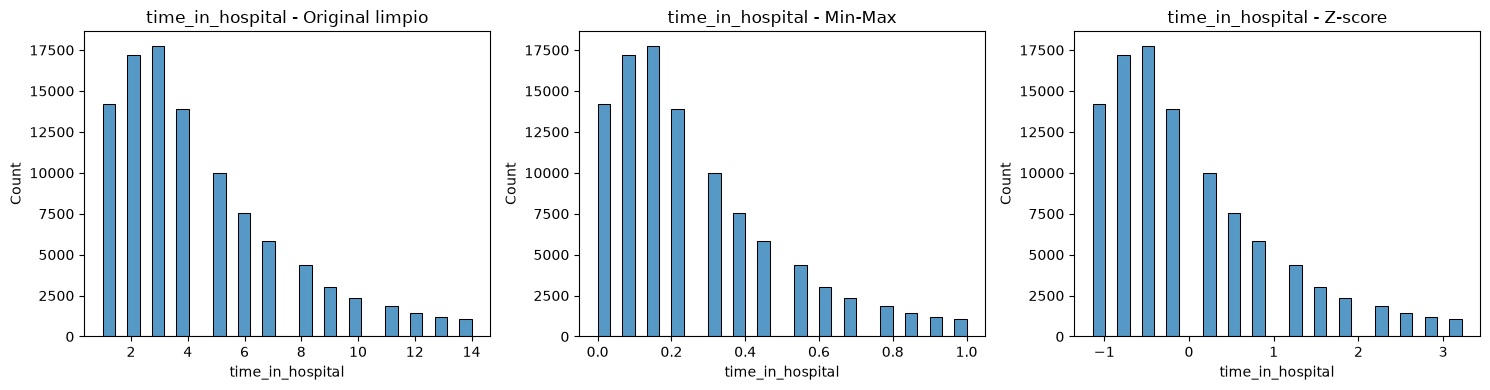

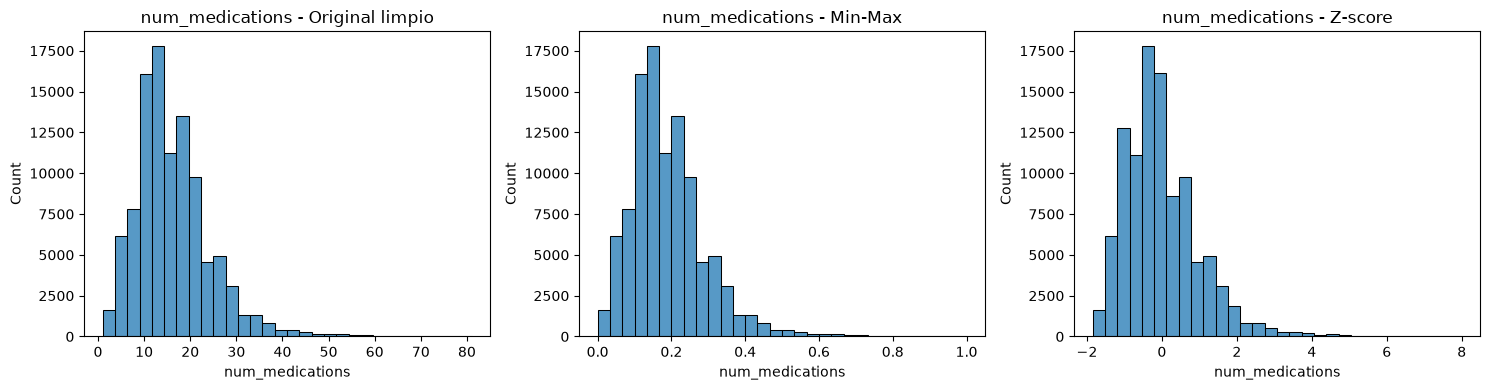

                     original    min-max    z-score
time_in_hospital     1.133999   1.133999   1.133999
num_lab_procedures  -0.236544  -0.236544  -0.236544
num_procedures       1.316415   1.316415   1.316415
num_medications      1.326672   1.326672   1.326672
number_outpatient    8.832959   8.832959   8.832959
number_emergency    22.855582  22.855582  22.855582
number_inpatient     3.614139   3.614139   3.614139


In [25]:
#Graficos de las tres versiones para dos variables
for var in ["time_in_hospital", "num_medications"]:
    fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
    for eje, datos, titulo in zip(ejes, [X, X_norm, X_std], ["Original limpio", "Min-Max", "Z-score"]):
        sns.histplot(datos[var], bins=30, ax=eje)
        eje.set_title(f"{var} - {titulo}")
    plt.tight_layout()
    plt.show()

#La forma se conserva: la asimetria es igual en las tres versiones
print(pd.DataFrame({"original": X.skew(), "min-max": X_norm.skew(), "z-score": X_std.skew()}))

In [26]:
#Calculo manual con cinco valores de num_medications
var = "num_medications"
x_min, x_max = X[var].min(), X[var].max()
mu, sigma = X[var].mean(), X[var].std(ddof=0)
print(f"Parámetros: x_min = {x_min}, x_max = {x_max}, media = {mu:.4f}, desviación = {sigma:.4f}\n")

valores = X[var].drop_duplicates().sort_values()
posiciones = np.linspace(0, len(valores) - 1, 5).round().astype(int)
muestra = valores.iloc[posiciones]

filas = []
for indice, x in muestra.items():
    mm = (x - x_min) / (x_max - x_min)
    z = (x - mu) / sigma
    print(f"x = {x}: Min-Max = ({x} - {x_min}) / ({x_max} - {x_min}) = {mm:.6f} | Z = ({x} - {mu:.4f}) / {sigma:.4f} = {z:.6f}")
    filas.append({"x": x, "minmax_manual": mm, "minmax_python": X_norm.loc[indice, var],
                  "z_manual": z, "z_python": X_std.loc[indice, var]})

tabla_manual = pd.DataFrame(filas)
display(tabla_manual)
assert np.allclose(tabla_manual["minmax_manual"], tabla_manual["minmax_python"])
assert np.allclose(tabla_manual["z_manual"], tabla_manual["z_python"])
print("\nEl cálculo manual coincide con Python")

Parámetros: x_min = 1, x_max = 81, media = 16.0218, desviación = 8.1275

x = 1: Min-Max = (1 - 1) / (81 - 1) = 0.000000 | Z = (1 - 16.0218) / 8.1275 = -1.848268
x = 19: Min-Max = (19 - 1) / (81 - 1) = 0.225000 | Z = (19 - 16.0218) / 8.1275 = 0.366428
x = 38: Min-Max = (38 - 1) / (81 - 1) = 0.462500 | Z = (38 - 16.0218) / 8.1275 = 2.704163
x = 57: Min-Max = (57 - 1) / (81 - 1) = 0.700000 | Z = (57 - 16.0218) / 8.1275 = 5.041898
x = 81: Min-Max = (81 - 1) / (81 - 1) = 1.000000 | Z = (81 - 16.0218) / 8.1275 = 7.994826


,x,minmax_manual,minmax_python,z_manual,z_python
0,1,0.0000,0.0000,-1.848268,-1.848268
1,19,0.2250,0.2250,0.366428,0.366428
2,38,0.4625,0.4625,2.704163,2.704163
3,57,0.7000,0.7000,5.041898,5.041898
4,81,1.0000,1.0000,7.994826,7.994826



El cálculo manual coincide con Python


**Exporte las siete variables a datos_normalizados.csv y datos_estandarizados.csv; conserve el mismo orden e índice de referencia en ambas versiones.**

In [27]:
#Exportamos (el indice_referencia es la posicion de la fila en el CSV original)
X_norm.to_csv("datos_normalizados.csv", index=True, index_label="indice_referencia")
X_std.to_csv("datos_estandarizados.csv", index=True, index_label="indice_referencia")

#Correspondencia con los registros originales
pd.DataFrame({"indice_referencia": X.index,
              "encounter_id": df_clean.loc[X.index, "encounter_id"].values,
              "patient_nbr": df_clean.loc[X.index, "patient_nbr"].values}
             ).to_csv("correspondencia_registros.csv", index=False)

#Comprobamos leyendo los archivos de nuevo
n = pd.read_csv("datos_normalizados.csv", index_col="indice_referencia")
z = pd.read_csv("datos_estandarizados.csv", index_col="indice_referencia")
original = pd.read_csv("hospitalizaciones_diabetes_original.csv", usecols=VARS)

assert n.index.equals(z.index)
assert list(n.columns) == list(z.columns) == VARS
assert np.allclose(n.values, X_norm.values) and np.allclose(z.values, X_std.values)
assert (original.loc[n.index, VARS].values == X.values).all()
print("Exportación correcta:", n.shape, z.shape)

Exportación correcta: (101766, 7) (101766, 7)


In [28]:
#Resumen de resultados para responder las preguntas de analisis
print("Hospitalizaciones analizadas:", len(df_clean), "| pacientes únicos:", df_clean["patient_nbr"].nunique())
print("\nPregunta 1: asimetría y % de atípicos")
print(pd.DataFrame({"asimetria": X.skew(), "% atipicos": tabla_iqr["porcentaje"]}))
print("\nPregunta 2: medianas por categoría de readmitted")
print(df_clean.groupby("readmitted")[["time_in_hospital", "num_medications", "number_inpatient"]].median().reindex(["NO", ">30", "<30"]))
print("\nMedias por categoría de readmitted")
print(df_clean.groupby("readmitted")[["time_in_hospital", "num_medications", "number_inpatient"]].mean().reindex(["NO", ">30", "<30"]))

Hospitalizaciones analizadas: 101766 | pacientes únicos: 71518

Pregunta 1: asimetría y % de atípicos
                    asimetria  % atipicos
time_in_hospital     1.133999    2.212920
num_lab_procedures  -0.236544    0.140518
num_procedures       1.316415    4.868031
num_medications      1.326672    2.512627
number_outpatient    8.832959   16.448519
number_emergency    22.855582   11.185465
number_inpatient     3.614139    6.926675

Pregunta 2: medianas por categoría de readmitted
            time_in_hospital  num_medications  number_inpatient
readmitted                                                     
NO                       3.0             14.0               0.0
>30                      4.0             15.0               0.0
<30                      4.0             16.0               0.0

Medias por categoría de readmitted
            time_in_hospital  num_medications  number_inpatient
readmitted                                                     
NO                  4.254429



## Preguntas de reflexión

**1. ¿Por qué un código categórico numérico no debe escalarse como una medición?** Porque el número es solo una etiqueta. El código 6 no es "seis veces" el código 1, y al escalarlo se crea un orden y una distancia que no existen.

**2. ¿Cómo afectaría un valor extremo a Min-Max y a Z-score?** En Min-Max el extremo pasa a ser el máximo y el resto de los datos se comprime cerca de 0. En Z-score el extremo mueve la media y aumenta la desviación estándar, y él mismo obtiene un z muy grande.

**3. ¿Por qué una readmisión del mismo paciente no es necesariamente un duplicado?** Porque es una nueva hospitalización, con otro `encounter_id` y valores propios. Un duplicado es la misma fila repetida. Eliminar las readmisiones borraría lo que se quiere estudiar.

**4. ¿Qué diferencia hay entre cambiar de escala y corregir una distribución asimétrica?** Cambiar de escala (Min-Max o Z-score) es una transformación lineal y no cambia la forma ni la asimetría. Para corregir la asimetría se necesita una transformación no lineal, como el logaritmo o la raíz cuadrada.

**5. ¿Cómo evitaría la fuga de información si posteriormente entrenara un modelo?** Separando primero entrenamiento y prueba (sin repartir al mismo paciente en los dos), haciendo `fit` del escalador solo con el entrenamiento y usando `transform` en los demás conjuntos.
